# EN3160 Image Processing and Machine Vision
## Assignment 3: Neural Networks
GUNATHUNGA U.A.  
230218G  
[GitHub repository](https://github.com/Upani-Gunathunga/EN3160-A3-Neural-Networks)


In [63]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import copy
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

output_path = Path('results')
output_path.mkdir(exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)
print('Device:', device)
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('Working folder:', Path.cwd())


Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Working folder: c:\Users\asus\Documents\semester 5\CV\ass3


## QUESTION 1
### Important parts of code




Weight initialization uses standard deviation $1/\sqrt{\text{input count}}$. The learning rate is 0.1 with decay 0.9.


Device: cuda
Epoch 1/10, Loss: 1.8062101985216141
Epoch 2/10, Loss: 1.6728562210798263
Epoch 3/10, Loss: 1.6113708715438844
Epoch 4/10, Loss: 1.566626722574234
Epoch 5/10, Loss: 1.5266632050275804
Epoch 6/10, Loss: 1.491914845585823
Epoch 7/10, Loss: 1.463333183646202
Epoch 8/10, Loss: 1.4365388722419739
Epoch 9/10, Loss: 1.4133375564813613
Epoch 10/10, Loss: 1.3922812718749047


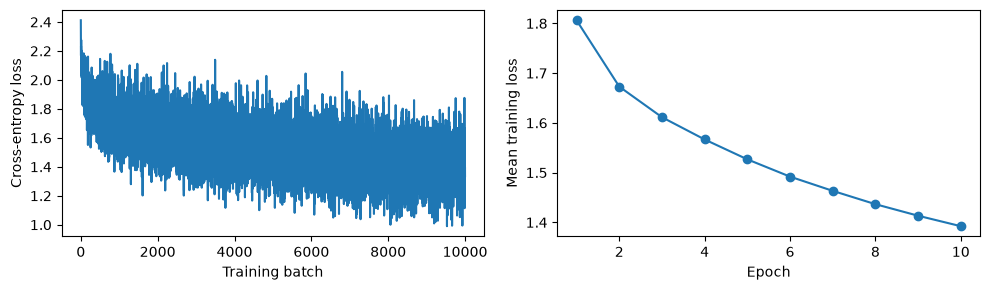

Training accuracy: 53.45%
Test accuracy: 47.77%


In [64]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print('Device:', device)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
# std = 1e-5       # Unused with current initialization

# w = torch.randn(Din, K) * std  # One layer: directly map input to output
# b = torch.zeros(K)
########################################

H = 100
# Initialize weights and biases
w1 = torch.randn(Din, H, device=device) / (Din ** 0.5)
b1 = torch.zeros(H, device=device)
w2 = torch.randn(H, K, device=device) / (H ** 0.5)
b2 = torch.zeros(K, device=device)
##########################################

# Hyperparameters
iterations = 10
lr = 0.1          # Learning rate
lr_decay = 0.9    # Learning rate decay
reg = 0           # Regularization
loss_history = []
epoch_losses = []


# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        #-----------move batch to device----------
        inputs = inputs.to(device)
        labels = labels.to(device)
       
        Ntr = inputs.shape[0]  # Batch size

        # x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        # y_train_onehot = nn.functional.one_hot(labels, K).float()

        #-----------input notation----------
        x1 = inputs.view(Ntr, -1)
        y = nn.functional.one_hot(labels, K).float()
       

        ############### middle layer and sigmoid activation #######

        #-----------forward pass 
        a1 = x1 @ w1 + b1
        a2 = torch.sigmoid(a1)
        a3 = a2 @ w2 + b2

        log_yhat = torch.log_softmax(a3, dim=1)
        yhat = log_yhat.exp()
    

        #-----------cross-entropy loss----------
        L = -(y * log_yhat).sum() / Ntr
        L = L + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        loss_history.append(L.item())
        running_loss += L.item()
        #-------------------------------------
       
        #-----------backpropagation ----------

        #  Output score gradients
        dL_da3 = (yhat - y) / Ntr

        # Output weights and biases
        dL_dw2 = a2.T @ dL_da3 + 2 * reg * w2
        dL_db2 = dL_da3.sum(dim=0)

        #  Hidden activation gradients
        dL_da2 = dL_da3 @ w2.T

        # sigmoid
        dL_da1 = dL_da2 * a2 * (1 - a2)

        #  Input weights and biases
        dL_dw1 = x1.T @ dL_da1 + 2 * reg * w1
        dL_db1 = dL_da1.sum(dim=0)

        # Parameter update
        w1 -= lr * dL_dw1
        b1 -= lr * dL_db1
        w2 -= lr * dL_dw2
        b2 -= lr * dL_db2
        #-----------------------

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    epoch_losses.append(running_loss / len(trainloader))

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(loss_history)
axes[0].set_xlabel('Training batch')
axes[0].set_ylabel('Cross-entropy loss')

axes[1].plot(range(1, iterations + 1), epoch_losses, marker='o')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean training loss')

plt.tight_layout()
plt.show()


# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Ntr = inputs.shape[0]

        #-----------forward pass with new notation----------
        x1 = inputs.view(Ntr, -1)
        a1 = x1 @ w1 + b1
        a2 = torch.sigmoid(a1)
        a3 = a2 @ w2 + b2

        #  for choosing the class
        predicted_train = torch.argmax(a3, dim=1)
        #--------------end------------------------

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Nte = inputs.shape[0]

    
        #-----------forward pass ----------
        x1 = inputs.view(Nte, -1)
        a1 = x1 @ w1 + b1
        a2 = torch.sigmoid(a1)
        a3 = a2 @ w2 + b2

        #  for choosing the class
        predicted_test = torch.argmax(a3, dim=1)
        #--------------end------------------------

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

In [65]:
#-----------results and comparison----------
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

output_path = Path('results')
output_path.mkdir(exist_ok=True)
q1_results = pd.DataFrame({
    'Split': ['Training', 'Test'],
    'Correct': [correct_train, correct_test],
    'Total': [total_train, total_test],
    'Accuracy (%)': [train_acc, test_acc]
})
display(q1_results)
q1_results.to_csv(output_path / 'q1_results.csv', index=False)
pd.DataFrame({'epoch': range(1, iterations + 1), 'loss': epoch_losses}).to_csv(
    output_path / 'q1_epoch_losses.csv', index=False)
gap = train_acc - test_acc
display(Markdown(
    f'After {iterations} epochs, training accuracy is {train_acc:.2f}% and '
    f'test accuracy is {test_acc:.2f}%.  \n'
    f'The train minus test gap is {gap:.2f} percentage points.  \n'
    f'Mean training-batch loss changed from {epoch_losses[0]:.4f} '
    f'to {epoch_losses[-1]:.4f}.'))
#--------------end------------------------

,Split,Correct,Total,Accuracy (%)
0,Training,26724,50000,53.448
1,Test,4777,10000,47.770


After 10 epochs, training accuracy is 53.45% and test accuracy is 47.77%.  
The train minus test gap is 5.68 percentage points.  
Mean training-batch loss changed from 1.8062 to 1.3923.

### Image results and comparison of results

- Mean training loss drops from 1.8062 to 1.3923 over ten epochs, so the network is learning. The curve is still falling at the end, which suggests learning has not fully settled.

- Batch loss jumps around because each batch contains different images. The epoch average gives a clearer view of the overall improvement.

- Training accuracy reaches 53.45%, while test accuracy reaches 47.77%. The gap of 5.68 percentage points shows that the network performs better on images it has already trained on.

- Even training accuracy is fairly low, so overfitting alone does not explain the result. One hidden layer with 100 sigmoid nodes may not learn enough useful features within ten epochs.

- Flattening keeps all the pixel values, but the dense layers do not directly use neighbouring pixels as image patches. This makes learning local patterns harder than with convolution layers.

- The learning rate gets smaller after each epoch, reducing the update size. This may help the loss decrease more steadily.



## QUESTION 2
### Important parts of code


In [66]:
#fixed

transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
batch_size = 50
trainset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform)
train_eval_loader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=False, num_workers=0)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0)
#--------------------------------------
print('Train:', len(trainset), 'Test:', len(testset))
print('Image shape:', tuple(trainset[0][0].shape))


Train: 60000 Test: 10000
Image shape: (1, 32, 32)


#### 2(a)
The network follows the LeNet-5 layout. Tanh provides the nonlinearity.


In [67]:
#  from lec slides lenet5

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.Conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.Conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.tanh(self.Conv1(x))
        x = nn.functional.avg_pool2d(x, kernel_size=2, stride=2)
        x = torch.tanh(self.Conv2(x))
        x = nn.functional.avg_pool2d(x, kernel_size=2, stride=2)
        x = x.view(-1, 16*5*5)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)
        return x
#--------------------------------------


#### 2(b)

In [ ]:

class SmallCNN(nn.Module):
#--------------- from https://github.com/chabi1773/EN3150_Assignment_03_Team-FrameX.git where 
# i implemented a modified vgg16+lenet architecture------------------
    def __init__(self):
        super().__init__()
        self.Conv1 = nn.Conv2d(1,6,kernel_size=3,stride=1,padding=1)
        #maxpooling doesnt change the cin or cout.. only downsample the picture
        self.batch_norm1 = nn.BatchNorm2d(6)
        self.Conv2 = nn.Conv2d(6,16,kernel_size=3,stride=1,padding=1)
        self.batch_norm2 = nn.BatchNorm2d(16)

        # Added third convolution and dropout before fc
        self.Conv3 = nn.Conv2d(16,16,kernel_size=3,stride=1,padding=1)
        self.batch_norm3 = nn.BatchNorm2d(16)
        self.dropout = nn.Dropout(0.25)

        self.fc1    = nn.Linear(16*4*4,120)
        self.fc2    = nn.Linear(120,84)
        self.fc3    = nn.Linear(84,10)

        
    def forward(self,x):
        x = torch.relu(self.batch_norm1(self.Conv1(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.relu(self.batch_norm2(self.Conv2(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)

        # Added third convolution
        x = torch.relu(self.batch_norm3(self.Conv3(x)))

        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = x.view(-1,16*4*4)

        # Added dropout
        x = self.dropout(x)

        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x


### 02 (c)

In [69]:

def train_epoch(model, loader, optimizer1, criterion, frozen=False):
    model.train()
    if frozen:
        model.eval()
        model.fc.train()
    loss_sum = 0.0
    total = 0
    for images, label in loader:
        images, label = images.to(device), label.to(device)
        
        #----------------
        output = model(images)
        loss = criterion(output, label)
        optimizer1.zero_grad()
        loss.backward()
        optimizer1.step()
        #--------------------------------------
        loss_sum += loss.item() * label.size(0)
        total += label.size(0)
    return loss_sum / total
#--------------------------------------


In [70]:
# Added loss
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            output = model(images)
            loss = criterion(output, labels)
            predicted = output.argmax(dim=1)
            loss_sum += loss.item() * labels.size(0)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predicted.cpu().tolist())
    return loss_sum / total, 100 * correct / total, all_labels, all_predictions


In [71]:
# Added per-epoch result collection
def fit_model(model, trainloader, train_eval_loader, eval_loader,
              optimizer, epochs, frozen=False, scheduler=None):
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.time()
    for epoch in range(epochs):
        update_loss = train_epoch(model, trainloader, optimizer, criterion, frozen)
        train_loss, train_acc, _, _ = evaluate(model, train_eval_loader, criterion)
        eval_loss, eval_acc, _, _ = evaluate(model, eval_loader, criterion)
        history.append([epoch + 1, train_loss, eval_loss, train_acc, eval_acc])
        print(f'Epoch {epoch + 1:2d} | train loss {train_loss:.4f} | '
              f'eval loss {eval_loss:.4f} | train {train_acc:.2f}% | eval {eval_acc:.2f}%')
        if scheduler is not None:
            scheduler.step()
    elapsed = time.time() - start
    names = ['epoch', 'train_loss', 'eval_loss', 'train_accuracy', 'eval_accuracy']
    return pd.DataFrame(history, columns=names), elapsed


In [72]:
q2_models = {}
q2_results = {}
q2_times = {}
for name in ['LeNet5', 'SmallCNN']:
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)
    trainloader = torch.utils.data.DataLoader(
        trainset, batch_size=50, shuffle=True, num_workers=0, generator=generator)
    if name == 'LeNet5':
        model = LeNet5().to(device)
    else:
        model = SmallCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    print(name, 'parameters:', sum(p.numel() for p in model.parameters()))
    history, elapsed = fit_model(
        model, trainloader, train_eval_loader, testloader, optimizer, 10)
    q2_models[name] = model
    q2_results[name] = history
    q2_times[name] = elapsed
    


LeNet5 parameters: 61706
Epoch  1 | train loss 0.0905 | eval loss 0.0927 | train 97.26% | eval 97.18%
Epoch  2 | train loss 0.0536 | eval loss 0.0622 | train 98.32% | eval 98.08%
Epoch  3 | train loss 0.0407 | eval loss 0.0593 | train 98.78% | eval 98.10%
Epoch  4 | train loss 0.0373 | eval loss 0.0607 | train 98.79% | eval 98.19%
Epoch  5 | train loss 0.0364 | eval loss 0.0644 | train 98.75% | eval 97.97%
Epoch  6 | train loss 0.0223 | eval loss 0.0510 | train 99.31% | eval 98.47%
Epoch  7 | train loss 0.0316 | eval loss 0.0563 | train 98.94% | eval 98.29%
Epoch  8 | train loss 0.0177 | eval loss 0.0491 | train 99.43% | eval 98.59%
Epoch  9 | train loss 0.0208 | eval loss 0.0521 | train 99.28% | eval 98.38%
Epoch 10 | train loss 0.0155 | eval loss 0.0453 | train 99.48% | eval 98.66%
SmallCNN parameters: 45190
Epoch  1 | train loss 0.0716 | eval loss 0.0724 | train 97.67% | eval 97.58%
Epoch  2 | train loss 0.0456 | eval loss 0.0511 | train 98.61% | eval 98.42%
Epoch  3 | train loss 0.

### Image results and comparison of results

,epoch,train_loss,eval_loss,train_accuracy,eval_accuracy
0,1,0.0905,0.0927,97.2617,97.18
1,2,0.0536,0.0622,98.3233,98.08
2,3,0.0407,0.0593,98.7817,98.10
3,4,0.0373,0.0607,98.7883,98.19
4,5,0.0364,0.0644,98.7500,97.97
5,6,0.0223,0.0510,99.3083,98.47
6,7,0.0316,0.0563,98.9383,98.29
7,8,0.0177,0.0491,99.4333,98.59
8,9,0.0208,0.0521,99.2817,98.38
9,10,0.0155,0.0453,99.4767,98.66


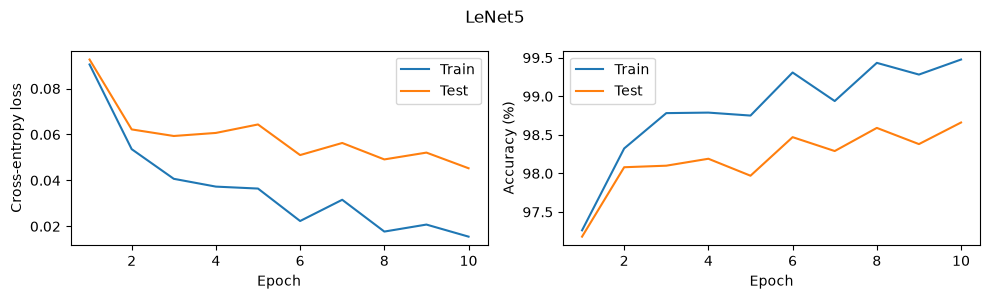

,epoch,train_loss,eval_loss,train_accuracy,eval_accuracy
0,1,0.0716,0.0724,97.6717,97.58
1,2,0.0456,0.0511,98.6133,98.42
2,3,0.0354,0.0391,98.9117,98.77
3,4,0.0315,0.0375,98.9900,98.81
4,5,0.0306,0.0412,99.0250,98.70
5,6,0.0292,0.0396,99.1183,98.62
6,7,0.0227,0.0332,99.2917,98.89
7,8,0.0222,0.0374,99.3067,98.89
8,9,0.0232,0.0419,99.2450,98.82
9,10,0.0162,0.0328,99.4567,99.01


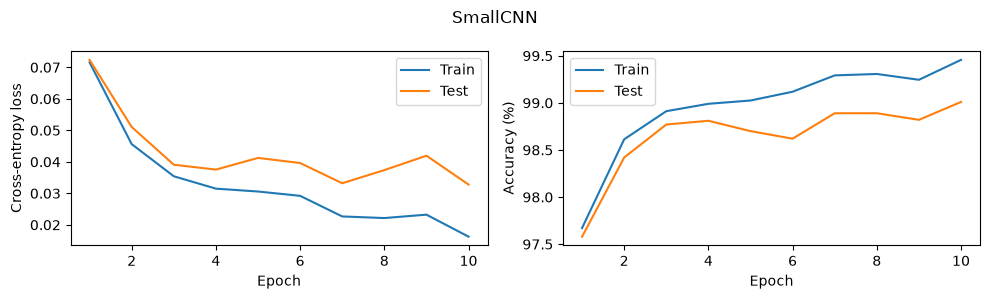

In [73]:
def plot_history(history, name, eval_name, filename):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(history.epoch, history.train_loss, label='Train')
    axes[0].plot(history.epoch, history.eval_loss, label=eval_name)
    axes[1].plot(history.epoch, history.train_accuracy, label='Train')
    axes[1].plot(history.epoch, history.eval_accuracy, label=eval_name)
    axes[0].set_ylabel('Cross-entropy loss')
    axes[1].set_ylabel('Accuracy (%)')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.legend()
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(output_path / filename, dpi=160)
    plt.show()

for name in q2_results:
    display(q2_results[name].round(4))
    plot_history(q2_results[name], name, 'Test', f'q2_{name}_curves.png')


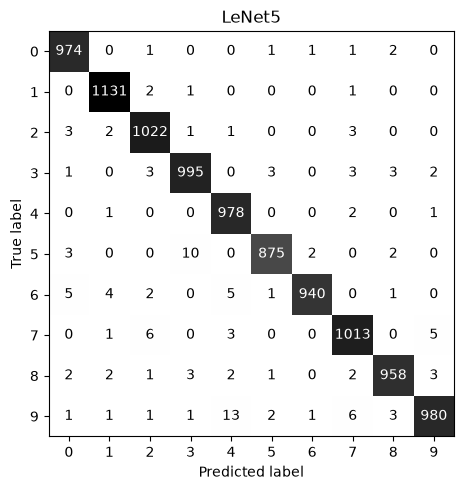

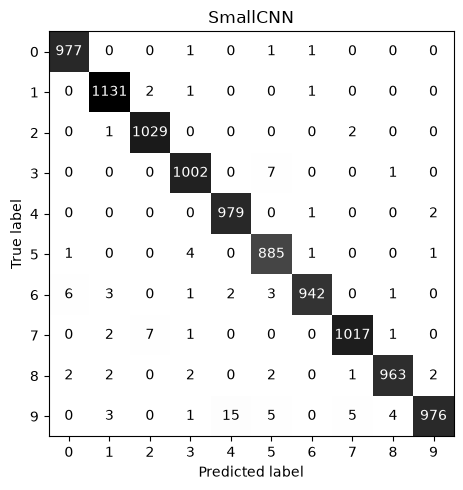

In [74]:
# Added comparison display
# Display both test confusion matrices
q2_matrices = {}
for name, model in q2_models.items():
    loss, accuracy, labels, predictions = evaluate(model, testloader, nn.CrossEntropyLoss())
    matrix = confusion_matrix(labels, predictions, labels=list(range(10)))
    q2_matrices[name] = matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(matrix, display_labels=list(range(10))).plot(
        ax=ax, cmap='Greys', colorbar=False, values_format='d')
    ax.set_title(name)
    fig.tight_layout()
    fig.savefig(output_path / f'q2_{name}_confusion.png', dpi=160)
    plt.show()


In [75]:
rows = []
for name in q2_results:
    last = q2_results[name].iloc[-1]
    count = sum(p.numel() for p in q2_models[name].parameters())
    rows.append([name, count, last.train_accuracy, last.eval_accuracy,
                 last.train_loss, last.eval_loss, q2_times[name]])
q2_summary = pd.DataFrame(rows, columns=[
    'Model', 'Parameters', 'Train accuracy (%)', 'Test accuracy (%)',
    'Train loss', 'Test loss', 'Seconds'])
display(q2_summary.round(4))
q2_summary.to_csv(output_path / 'q2_summary.csv', index=False)
delta = q2_results['SmallCNN'].iloc[-1].eval_accuracy - q2_results['LeNet5'].iloc[-1].eval_accuracy
display(Markdown(f'SmallCNN minus LeNet5 test accuracy is {delta:.2f} percentage points.'))
for name, matrix in q2_matrices.items():
    errors = matrix.copy()
    np.fill_diagonal(errors, 0)
    actual, predicted = np.unravel_index(errors.argmax(), errors.shape)
    if errors.max() > 0:
        print(f'{name}: largest error count is digit {actual} predicted as {predicted}, '
              f'{errors[actual, predicted]} images.')


,Model,Parameters,Train accuracy (%),Test accuracy (%),Train loss,Test loss,Seconds
0,LeNet5,61706,99.4767,98.66,0.0155,0.0453,260.0911
1,SmallCNN,45190,99.4567,99.01,0.0162,0.0328,277.2208


SmallCNN minus LeNet5 test accuracy is 0.35 percentage points.

LeNet5: largest error count is digit 9 predicted as 4, 13 images.
SmallCNN: largest error count is digit 9 predicted as 4, 15 images.


Discussion of Results

- SmallCNN has slightly higher test accuracy 99.01% vs 98.67%, with lower test loss.
- Its extra convolution, batch normalization and dropout may help it learn features and generalize better.
- LeNet5 has a larger train–test accuracy gap of 0.73 vs 0.45 percentage points, suggesting slightly more overfitting.

- SmallCNN uses fewer parameters, but takes about 13 seconds longer because it performs more convolution and normalization operations.
- Both confuse 9 with 4 most often. SmallCNN makes this mistake slightly more as it makes  15 times compared to 13.

## QUESTION 3
### Important parts of code

In [76]:
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.datasets.utils import download_and_extract_archive

data_path = Path('data')
hymen_path = data_path / 'hymenoptera_data'
if not hymen_path.exists():
    download_and_extract_archive(
        'https://download.pytorch.org/tutorial/hymenoptera_data.zip',
        download_root=str(data_path))
assert (hymen_path / 'train').is_dir()
assert (hymen_path / 'val').is_dir()
weights = ResNet18_Weights.IMAGENET1K_V1
epochs = 25
batch_size = 4


In [78]:
# Question 3 tutorial preprocessing
# https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
trainset = torchvision.datasets.ImageFolder(hymen_path / 'train', train_transform)
train_eval_set = torchvision.datasets.ImageFolder(hymen_path / 'train', eval_transform)
valset = torchvision.datasets.ImageFolder(hymen_path / 'val', eval_transform)
assert trainset.class_to_idx == valset.class_to_idx
class_names = trainset.classes
train_eval_loader = torch.utils.data.DataLoader(
    train_eval_set, batch_size=batch_size, shuffle=False, num_workers=0)
valloader = torch.utils.data.DataLoader(
    valset, batch_size=batch_size, shuffle=False, num_workers=0)
print('Classes:', class_names)
print('Train:', len(trainset), 'Validation:', len(valset))
#--------------------------------------


Classes: ['ants', 'bees']
Train: 244 Validation: 153



[PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html). 




| Method | What learns |
|---|---|
| Fine-tuning | All ResNet18 parameters, including the new two-class layer |
| Feature extraction | Only the new two-class layer's parameters |

Both methods start from ImageNet1K weights and run for 25 epochs. The two output classes are ants and bees.

In [79]:
#---------------copied from tutorial


import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

cudnn.benchmark = True
plt.ion()   # interactive mode
#----------end----------------


In [80]:
# Added dataset download
from pathlib import Path
from torchvision.datasets.utils import download_and_extract_archive
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

output_path = Path('results')
output_path.mkdir(exist_ok=True)
if not Path('data/hymenoptera_data').exists():
    download_and_extract_archive(
        'https://download.pytorch.org/tutorial/hymenoptera_data.zip',
        download_root='data')


In [81]:
#--------------- from tutorial
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}
#----------end----------------


In [82]:
#--------------- from tutorial
data_dir = 'data/hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
#----------end----------------


In [83]:

# Tutorial code
dataloaders = {}
for phase in ['train', 'val']:
    dataloaders[phase] = torch.utils.data.DataLoader(
        image_datasets[phase], batch_size=4,
        shuffle=True, num_workers=4)


In [84]:
#--------------- from tutorial
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

# We want to be able to train our model on an `accelerator <https://pytorch.org/docs/stable/torch.html#accelerators>`__
# such as CUDA, MPS, MTIA, or XPU. If the current accelerator is available, we will use it. Otherwise, we use the CPU.

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")
#----------end----------------


Using cuda device


Training uses random crops and flips. 
Validation uses a fixed center crop. 
Both use 224 by 224 RGB images and ImageNet normalization.
The folder called `val` is a validation set, not an independent test set. 
The notebook prints the actual image counts.
The added loader cell uses 4 workers . Batch size 4.

In [85]:
# Added dataset counts
print('Classes:', class_names)
print('Images:', dataset_sizes)

Classes: ['ants', 'bees']
Images: {'train': 244, 'val': 153}


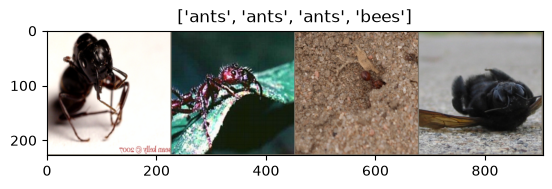

In [86]:
#--------------- from tutorial
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])
#----------end----------------


In [87]:
#--------------- from tutorial
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')
    
        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.double() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model
#----------end----------------


In [88]:
#--------------- from tutorial
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)
#----------end----------------


#### 3(a)
The pretrained classifier has 1000 outputs. Its replacement has two outputs and $512\times2+2=1026$ parameters.
SGD updates all parameters. The learning rate starts at 0.001 and is multiplied by 0.1 every seven epochs.

In [89]:
# Added repeatable initialization
torch.manual_seed(42)


In [90]:
#--------------- from tutorial
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to ``nn.Linear(num_ftrs, len(class_names))``.
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)
#----------end----------------


In [91]:
# Added timing
torch.manual_seed(42)
fine_start = time.time()

In [92]:
#--------------- from tutorial
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)
#----------end----------------


Epoch 0/24
----------
train Loss: 0.8077 Acc: 0.6107
val Loss: 0.5888 Acc: 0.7320

Epoch 1/24
----------
train Loss: 0.4311 Acc: 0.8115
val Loss: 0.2392 Acc: 0.9346

Epoch 2/24
----------
train Loss: 0.5099 Acc: 0.8074
val Loss: 0.3547 Acc: 0.8497

Epoch 3/24
----------
train Loss: 0.6152 Acc: 0.7664
val Loss: 0.3618 Acc: 0.8627

Epoch 4/24
----------
train Loss: 0.4287 Acc: 0.8238
val Loss: 0.3136 Acc: 0.8889

Epoch 5/24
----------
train Loss: 0.4989 Acc: 0.8197
val Loss: 0.2539 Acc: 0.9020

Epoch 6/24
----------
train Loss: 0.5045 Acc: 0.8156
val Loss: 0.6937 Acc: 0.8105

Epoch 7/24
----------
train Loss: 0.3869 Acc: 0.8484
val Loss: 0.2430 Acc: 0.9150

Epoch 8/24
----------
train Loss: 0.3825 Acc: 0.8852
val Loss: 0.2319 Acc: 0.9020

Epoch 9/24
----------
train Loss: 0.2544 Acc: 0.8975
val Loss: 0.2032 Acc: 0.9020

Epoch 10/24
----------
train Loss: 0.2961 Acc: 0.8730
val Loss: 0.2026 Acc: 0.9216

Epoch 11/24
----------
train Loss: 0.3189 Acc: 0.8770
val Loss: 0.2140 Acc: 0.9216

Ep

In [93]:
# Added saved result
fine_seconds = time.time() - fine_start
torch.save(model_ft.state_dict(), output_path / 'q3_fine_best.pt')


#### 3(b)
`requires_grad=False` freezes the existing parameters. The replacement final layer has trainable parameters by default. Its optimizer receives only `model_conv.fc.parameters()`.


In [94]:
# Added repeatable initialization
torch.manual_seed(42)


In [95]:
#--------------- from tutorial
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False #we are not training the whole model, only the last layer

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)
#----------end----------------


In [96]:
# Added timing
torch.manual_seed(42)
feature_start = time.time()


In [97]:
#--------------- from tutorial
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)
#----------end----------------


Epoch 0/24
----------
train Loss: 0.8891 Acc: 0.5861
val Loss: 0.6187 Acc: 0.6797

Epoch 1/24
----------
train Loss: 0.3717 Acc: 0.8074
val Loss: 0.2120 Acc: 0.9150

Epoch 2/24
----------
train Loss: 0.4642 Acc: 0.8156
val Loss: 0.1852 Acc: 0.9346

Epoch 3/24
----------
train Loss: 0.4955 Acc: 0.7869
val Loss: 0.2205 Acc: 0.9150

Epoch 4/24
----------
train Loss: 0.4082 Acc: 0.8361
val Loss: 0.2151 Acc: 0.9085

Epoch 5/24
----------
train Loss: 0.4924 Acc: 0.7787
val Loss: 0.1908 Acc: 0.9346

Epoch 6/24
----------
train Loss: 0.4274 Acc: 0.8279
val Loss: 0.3440 Acc: 0.8954

Epoch 7/24
----------
train Loss: 0.3400 Acc: 0.8484
val Loss: 0.1787 Acc: 0.9477

Epoch 8/24
----------
train Loss: 0.3286 Acc: 0.8689
val Loss: 0.2309 Acc: 0.9281

Epoch 9/24
----------
train Loss: 0.2537 Acc: 0.8893
val Loss: 0.1859 Acc: 0.9412

Epoch 10/24
----------
train Loss: 0.3094 Acc: 0.8852
val Loss: 0.2287 Acc: 0.9346

Epoch 11/24
----------
train Loss: 0.3467 Acc: 0.8566
val Loss: 0.2269 Acc: 0.9216

Ep

In [98]:
# Added saved result
feature_seconds = time.time() - feature_start
torch.save(model_conv.state_dict(), output_path / 'q3_feature_best.pt')


### Image results and comparison of results

In [99]:
# Added result reporting
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

output_path = Path('results')
output_path.mkdir(exist_ok=True)
q3_models = {'Fine-tuning': model_ft, 'Feature extraction': model_conv}
q3_times = {'Fine-tuning': fine_seconds, 'Feature extraction': feature_seconds}
q3_rows = []
q3_matrices = {}


In [100]:
# Evaluate the returned checkpoints
for name, model in q3_models.items():
    model.eval()
    scores = {}
    for phase in ['train', 'val']:
        loss_sum = 0.0
        correct = 0
        total = 0
        true_labels = []
        predicted_labels = []
        with torch.no_grad():
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                predictions = outputs.argmax(dim=1)
                loss_sum += loss.item() * labels.size(0)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)
                true_labels.extend(labels.cpu().tolist())
                predicted_labels.extend(predictions.cpu().tolist())
        scores[phase] = [loss_sum / total, 100 * correct / total]
        if phase == 'val':
            q3_matrices[name] = confusion_matrix(
                true_labels, predicted_labels, labels=list(range(len(class_names))))
    count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    q3_rows.append([name, scores['train'][0], scores['val'][0],
                   scores['train'][1], scores['val'][1], q3_times[name], count])


In [101]:
# Losses, accuracies and training time
q3_results = pd.DataFrame(q3_rows, columns=[
    'Method', 'Train loss', 'Validation loss',
    'Train accuracy (%)', 'Validation accuracy (%)',
    'Training time (s)', 'Trainable parameters'])
print('Results for the returned best-validation checkpoints')
display(q3_results.round(4))
q3_results.to_csv(output_path / 'q3_comparison.csv', index=False)
print('Training time includes the  training and validation loop.')



Results for the returned best-validation checkpoints


,Method,Train loss,Validation loss,Train accuracy (%),Validation accuracy (%),Training time (s),Trainable parameters
0,Fine-tuning,0.1931,0.2392,90.5738,93.4641,367.1925,11177538
1,Feature extraction,0.1127,0.1787,96.3115,94.7712,651.5725,1026


Training time includes the  training and validation loop.


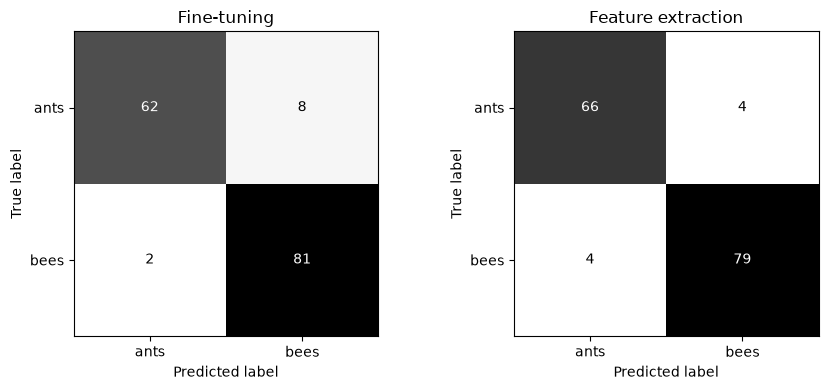

In [102]:
# Validation confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, q3_models):
    ConfusionMatrixDisplay(
        q3_matrices[name], display_labels=class_names).plot(
            ax=ax, cmap='Greys', colorbar=False, values_format='d')
    ax.set_title(name)
fig.tight_layout()
fig.savefig(output_path / 'q3_confusion.png', dpi=160)
plt.show()



In [103]:
# Compare measured results

for name in q3_models:
    matrix = q3_matrices[name]
    mistakes = int(matrix.sum() - np.trace(matrix))
    print(f'{name}: {mistakes} validation mistakes out of {matrix.sum()} images')


Fine-tuning: 10 validation mistakes out of 153 images
Feature extraction: 8 validation mistakes out of 153 images


Discussion of Results

- Feature extraction reaches 94.77% validation accuracy and makes 8 mistakes out of 153 images. Fine-tuning reaches 93.46% and makes 10 mistakes. The difference comes from just two images.

- Fine-tuning gets a higher training accuracy of 97.13%, while feature extraction gets 93.85%. But fine-tuning does worse on validation images, which suggests more overfitting.

- Feature extraction has a lower validation loss of 0.1787. Fine-tuning has a loss of 0.2031. The pretrained features seem useful for ants and bees, so keeping their weights fixed may help with this small dataset.

- Feature extraction trains only 1,026 parameters. Fine-tuning trains about 11.18 million. Updating fewer parameters reduces the backward calculations and helps explain why feature extraction finishes about 46 seconds sooner.

- Both methods still run the full ResNet18 forward pass, so feature extraction still needs much of the computation.

- Feature extraction works better in this run. But with only two  mistakes, we cannot say it will always perform better.
